# Probabilistic FDM — 非線形楕円型 PDE（数値解析 informed calibration）

PDE:
\[
-\Delta u + u^3 = f, \qquad (x,y)\in(0,1)^2,
\]
with \(u=0\) on \(\partial(0,1)^2\).

Prescribed solution:
\[
u^*(x,y)=\sin(\pi x)\sin(\pi y)+4\sin(4\pi x)\sin(4\pi y).
\]

観測モデル:
\[
f=\mathcal F_h(u)+\varepsilon,
\qquad
\mathcal F_h(u)=D_hu+u^3,
\qquad
\varepsilon\sim\mathcal N(0,C h^{2\tau}I).
\]

この版では hyperparameter を marginal likelihood grid search せず、FDM の数値解析情報から設定する。

- finite-difference order: \(p=2\)
- noise exponent: \(\tau=p=2\)
- length scale: \(\ell=h\)（mesh-resolved correlation scale）
- prior amplitude: \(\sigma_f=\|u_h\|_\infty\)（RMS も診断表示）
- discretisation-noise scale: \(C=\widehat C_h\) を target-grid FDM solution の coarsening defect から推定

したがって追加の \(h/2\) solve は不要。


In [1]:
using Plots
using LinearAlgebra
using SpecialFunctions
using Statistics
using SparseArrays
using Printf
println("Packages loaded.")


Packages loaded.


In [2]:
# 2次元 Matérnカーネル
function matern_kernel_2d(x1, x2; ν=1.5, ℓ=1.0, σf=1.0)
    r = sqrt(sum((x1 .- x2).^2))
    r == 0 && return σf^2
    z = sqrt(2ν) * r / ℓ
    if ν == 0.5
        return σf^2 * exp(-z)
    elseif ν == 1.5
        return σf^2 * (1 + z) * exp(-z)
    elseif ν == 2.5
        return σf^2 * (1 + z + z^2/3) * exp(-z)
    else
        return σf^2 * (2^(1-ν)/gamma(ν)) * z^ν * besselk(ν, z)
    end
end

function kernel_matrix_2d(XY1, XY2; ν=1.5, ℓ=1.0, σf=1.0)
    n1, n2 = size(XY1,1), size(XY2,1)
    K = zeros(n1, n2)
    for i in 1:n1, j in 1:n2
        K[i,j] = matern_kernel_2d(XY1[i,:], XY2[j,:]; ν=ν, ℓ=ℓ, σf=σf)
    end
    return K
end
println("2D Kernel defined.")


2D Kernel defined.


In [3]:
# ============================================================
# Grid setup and manufactured high-frequency solution
# ============================================================

function make_grid(Nx)
    dx = 1.0 / (Nx + 1)
    xs = [dx*i for i in 1:Nx]
    ys = [dx*j for j in 1:Nx]
    xy = hcat(
        [x for y in ys for x in xs],
        [y for y in ys for x in xs]
    )
    return dx, xy, Nx^2
end

# ------------------------------------------------------------
# Manufactured exact solution
#
# Low-frequency component + deliberately under-resolved
# high-frequency component.
#
# This makes the deterministic FDM error visible on coarse grids.
# ------------------------------------------------------------

u_true(x, y) =
    sin(pi*x)*sin(pi*y) +
    2.0*sin(6*pi*x)*sin(6*pi*y)

# -Delta u_exact
neg_lap_u(x, y) =
    2*pi^2*sin(pi*x)*sin(pi*y) +
    2.0 * 2*(6*pi)^2 * sin(6*pi*x)*sin(6*pi*y)

# Nonlinear elliptic PDE:
#   -Delta u + u^3 = f
f_rhs(x, y) =
    neg_lap_u(x,y) + u_true(x,y)^3

println("Grid and high-frequency manufactured solution defined.")


Grid and high-frequency manufactured solution defined.


In [4]:
# ============================================================
# 情報作用素 D_h = -Delta_h (線形部分, 疎行列)
# ============================================================
function make_Dh_2d(Nx, dx)
    N = Nx^2
    idx(i,j) = (j-1)*Nx + i
    rows, cols, vals = Int[], Int[], Float64[]
    for j in 1:Nx, i in 1:Nx
        k = idx(i,j)
        push!(rows,k); push!(cols,k); push!(vals, 4.0/dx^2)
        i>1   && (push!(rows,k); push!(cols,idx(i-1,j)); push!(vals,-1.0/dx^2))
        i<Nx  && (push!(rows,k); push!(cols,idx(i+1,j)); push!(vals,-1.0/dx^2))
        j>1   && (push!(rows,k); push!(cols,idx(i,j-1)); push!(vals,-1.0/dx^2))
        j<Nx  && (push!(rows,k); push!(cols,idx(i,j+1)); push!(vals,-1.0/dx^2))
    end
    return sparse(rows, cols, vals, N, N)
end

# 非線形情報作用素: F(u) = D_h*u + u^3
function nonlinear_F(u, Dh)
    return Dh*u + u.^3
end

# Jacobian: J(u) = D_h + diag(3*u^2)
function jacobian_F(u, Dh)
    return Matrix(Dh) + Diagonal(3*u.^2)
end

println("Dh and nonlinear operators defined.")


Dh and nonlinear operators defined.


In [5]:
# ============================================================
# 通常の nonlinear FDM 解 (Newton 法, prior なし)
# ============================================================
function newton_fdm(dx, Nx, f_vals; tol=1e-10, maxiter=100, verbose=true)
    N   = Nx^2
    Dh  = make_Dh_2d(Nx, dx)
    u   = zeros(N)
    converged = false

    for it in 1:maxiter
        F  = nonlinear_F(u, Dh) - f_vals
        J  = jacobian_F(u, Dh)
        du = J \ (-F)
        u .+= du

        if norm(du) < tol
            converged = true
            verbose && println("  FDM Newton converged at iter $(it)")
            break
        end
    end

    if !converged
        @warn "FDM Newton did not reach tolerance" Nx dx tol maxiter
    end
    return u
end

# ============================================================
# Coarsening-based calibration of C
#
# F_h(u) - f = c(x) h^p + higher-order terms.
# For the target-grid numerical solution u_h, evaluate the same
# nonlinear operator with a 2h Laplacian stencil:
#
#     defect = F_{2h}(u_h) - f
#
# and use the leading-order correction
#
#     c_hat = defect / ((2^p - 1) h^p).
#
# Boundary values are known to be zero, so no additional solve is needed.
# ============================================================
function estimate_C_coarsening_2d(u_h, dx, Nx; p=2)
    U = reshape(u_h, Nx, Nx)
    h2 = 2dx

    # Interior centers for which the ±2 stencil stays inside the
    # physical domain, allowing boundary value 0 at index 0 or Nx+1.
    centers = 2:(Nx-1)
    isempty(centers) && error("Nx must be at least 3 for the 2h defect estimator.")

    c_hat = Float64[]
    defect = Float64[]
    xy_defect = Tuple{Float64,Float64}[]

    # Grid-value accessor including homogeneous Dirichlet boundary.
    function uval(i, j)
        if i == 0 || i == Nx+1 || j == 0 || j == Nx+1
            return 0.0
        elseif 1 <= i <= Nx && 1 <= j <= Nx
            return U[i,j]
        else
            error("2h stencil left the physical domain")
        end
    end

    for j in centers, i in centers
        x = i * dx
        y = j * dx

        D2h_u = (
            4uval(i,j)
            - uval(i-2,j) - uval(i+2,j)
            - uval(i,j-2) - uval(i,j+2)
        ) / h2^2

        F2h_u = D2h_u + uval(i,j)^3
        d = F2h_u - f_rhs(x,y)
        c = d / ((2.0^p - 1.0) * dx^p)

        push!(defect, d)
        push!(c_hat, c)
        push!(xy_defect, (x,y))
    end

    C_hat = mean(c_hat .^ 2)
    return C_hat, c_hat, defect, xy_defect
end

# Oracle C for diagnostics only (uses prescribed exact solution).
# This is NOT used by the method.
function oracle_C_2d(dx, Nx; p=2)
    vals = Float64[]

    function ustar_grid(i,j)
        if i == 0 || i == Nx+1 || j == 0 || j == Nx+1
            return 0.0
        end
        return u_true(i*dx, j*dx)
    end

    for j in 1:Nx, i in 1:Nx
        x = i*dx
        y = j*dx
        Dh_u = (
            4ustar_grid(i,j)
            - ustar_grid(i-1,j) - ustar_grid(i+1,j)
            - ustar_grid(i,j-1) - ustar_grid(i,j+1)
        ) / dx^2
        e = Dh_u + u_true(x,y)^3 - f_rhs(x,y)
        push!(vals, e / dx^p)
    end

    return mean(vals .^ 2)
end

# ============================================================
# MAP 推定 (Newton / Gauss-Newton, prior + likelihood)
# ============================================================
function newton_map(dx, Nx, f_vals, K;
                    C=1.0, tau=2, u0=nothing,
                    tol=1e-10, maxiter=100, verbose=true)
    N         = Nx^2
    Dh        = make_Dh_2d(Nx, dx)
    u         = u0 === nothing ? zeros(N) : copy(u0)
    noise_var = C * dx^(2*tau)
    Sigma_inv = (1.0/noise_var) * I
    K_inv     = inv(Matrix(K) + 1e-8*I)
    converged = false

    for it in 1:maxiter
        F_val = nonlinear_F(u, Dh) - f_vals
        J     = jacobian_F(u, Dh)
        H     = J' * Sigma_inv * J + K_inv
        g     = J' * Sigma_inv * F_val + K_inv * u
        du    = H \ (-g)
        u .+= du

        if norm(du) < tol
            converged = true
            verbose && println("  MAP Newton converged at iter $(it)")
            break
        end
    end

    if !converged
        @warn "MAP Newton did not reach tolerance" Nx dx tol maxiter
    end
    return u
end

println("Newton and calibration functions defined.")


Newton and calibration functions defined.


In [6]:
# ============================================================
# Laplace 近似 (正しい定式化)
# 観測モデル: f = F(u) + epsilon
# 事後平均: mu_post = u_map　
# 事後分散: Sigma_post = K - K J^T (J K J^T + Sigma)^{-1} J K
# ============================================================
function laplace_posterior(u_map, xy, dx, Nx, K;
                            C=1.0, tau=2)
    N           = Nx^2
    Dh          = make_Dh_2d(Nx, dx)
    J           = jacobian_F(u_map, Dh)
    noise_var   = C * dx^(2*tau)
    Sigma_noise = noise_var * I

    JK       = J * K
    M        = Symmetric(JK * J' + Sigma_noise)
    L        = cholesky(M).L

    mu_post  = u_map
    V        = L \ JK
    Sig_post = K - V' * V
    std_post = sqrt.(max.(diag(Sig_post), 0.0))

    return mu_post, std_post
end
println("laplace_posterior defined.")


laplace_posterior defined.


# Simple grid search for \(\ell\) and \(C\)

This version intentionally removes the numerics-informed hyperparameter rules.

We:

1. fix \(\sigma_f\),
2. grid-search \(\ell\) and \(C\) using an approximate nonlinear Laplace marginal likelihood,
3. print the marginal-likelihood table,
4. show the LML heatmap,
5. use the selected \((\ell,C)\) to compute the GP/Laplace posterior,
6. plot the posterior against the exact solution and the standard FDM solution.


In [7]:
# ============================================================
# Settings
# ============================================================

Nx      = 6
nu_ker  = 1.5
tau     = 2

# Fixed prior amplitude
sigma_f = 3.0

# Direct search grids
ell_grid = [0.03, 0.05, 0.1, 0.2, 0.3, 0.5, 1.0, 2.0, 5.0]

C_grid = [
    1e-4,
    1e-3,
    1e-2,
    1e-1,
    1.0,
    10.0,
    1e2,
    1e3,
    1e4,
    1e5,
    1e6,
    1e7,
    1e8
]

dx, xy, N = make_grid(Nx)

u_star = [
    u_true(xy[k,1], xy[k,2])
    for k in 1:N
]

f_vals = [
    f_rhs(xy[k,1], xy[k,2])
    for k in 1:N
]

u_fdm = newton_fdm(
    dx,
    Nx,
    f_vals;
    verbose=false
)

println("Nx      = ", Nx)
println("h       = ", dx)
println("sigma_f = ", sigma_f)


Nx      = 6
h       = 0.14285714285714285
sigma_f = 3.0


In [8]:
# ============================================================
# Approximate nonlinear log marginal likelihood
#
# Laplace / Gauss-Newton approximation around the MAP
# ============================================================

function nonlinear_lml(
    ell,
    C;
    dx=dx,
    Nx=Nx,
    xy=xy,
    f_vals=f_vals,
    u_fdm=u_fdm,
    sigma_f=sigma_f,
    nu=nu_ker,
    tau=tau
)
    N = Nx^2

    K = Symmetric(
        kernel_matrix_2d(
            xy,
            xy;
            ν=nu,
            ℓ=ell,
            σf=sigma_f
        ) + 1e-8*I
    )

    # MAP
    u_map = newton_map(
        dx,
        Nx,
        f_vals,
        K;
        C=C,
        tau=tau,
        u0=u_fdm,
        verbose=false
    )

    Dh = make_Dh_2d(Nx, dx)

    r = nonlinear_F(u_map, Dh) - f_vals
    J = jacobian_F(u_map, Dh)

    noise_var = C * dx^(2tau)

    if !isfinite(noise_var) || noise_var <= 0
        return -Inf
    end

    Kmat  = Matrix(K)
    Kchol = cholesky(Symmetric(Kmat))

    Kinv_u = Kchol \ u_map

    data_term  = 0.5 * dot(r, r) / noise_var
    prior_term = 0.5 * dot(u_map, Kinv_u)

    Hpost = Symmetric(
        (J' * J) / noise_var +
        inv(Kmat)
    )

    Hchol = cholesky(Hpost)

    logdet_H = 2sum(log, diag(Hchol.L))
    logdet_K = 2sum(log, diag(Kchol.L))
    logdet_S = N * log(noise_var)

    lml =
        -(data_term + prior_term) -
        0.5*logdet_H -
        0.5*logdet_K -
        0.5*logdet_S -
        0.5*N*log(2π)

    return lml
end

println("nonlinear_lml defined.")


nonlinear_lml defined.


In [9]:
# ============================================================
# Grid search over ell and C
# ============================================================

lml_table = fill(-Inf, length(ell_grid), length(C_grid))

println("Running grid search ...")

for (i, ell) in enumerate(ell_grid)
    for (j, C) in enumerate(C_grid)
        try
            lml_table[i,j] = nonlinear_lml(ell, C)
        catch err
            @warn "LML failed" ell C exception=(err, catch_backtrace())
            lml_table[i,j] = -Inf
        end
    end
end

best_idx = argmax(lml_table)
best_i, best_j = Tuple(best_idx)

best_ell = ell_grid[best_i]
best_C   = C_grid[best_j]
best_lml = lml_table[best_i, best_j]

println()
println("=== Best hyperparameters ===")
@printf("ell     = %.6g\n", best_ell)
@printf("C       = %.6g\n", best_C)
@printf("sigma_f = %.6g\n", sigma_f)
@printf("LML     = %.6g\n", best_lml)


Running grid search ...

=== Best hyperparameters ===
ell     = 0.03
C       = 0.0001
sigma_f = 3
LML     = -270.906


In [10]:
# ============================================================
# Marginal-likelihood table
# ============================================================

println("\n=== Marginal likelihood table ===")

@printf("%-10s", "ell \\ C")
for C in C_grid
    @printf("%12.2e", C)
end
println()

println("-"^(10 + 12*length(C_grid)))

for (i, ell) in enumerate(ell_grid)
    @printf("%-10.3g", ell)

    for j in eachindex(C_grid)
        val = lml_table[i,j]

        if isfinite(val)
            @printf("%12.2f", val)
        else
            @printf("%12s", "-Inf")
        end
    end

    println()
end

println()
@printf(
    "Best: ell=%.6g, C=%.6g, LML=%.6g\n",
    best_ell,
    best_C,
    best_lml
)



=== Marginal likelihood table ===
ell \ C       1.00e-04    1.00e-03    1.00e-02    1.00e-01    1.00e+00    1.00e+01    1.00e+02    1.00e+03    1.00e+04    1.00e+05    1.00e+06    1.00e+07    1.00e+08
----------------------------------------------------------------------------------------------------------------------------------------------------------------------
0.03           -270.91     -270.91     -270.91     -270.91     -270.91     -270.91     -270.91     -270.91     -270.91     -270.91     -270.94     -271.26     -273.87
0.05           -272.13     -272.13     -272.13     -272.13     -272.13     -272.13     -272.13     -272.13     -272.13     -272.14     -272.17     -272.46     -274.87
0.1            -283.16     -283.16     -283.16     -283.16     -283.16     -283.16     -283.16     -283.16     -283.16     -283.16     -283.17     -283.25     -283.98
0.2            -364.16     -364.16     -364.16     -364.16     -364.16     -364.16     -364.16     -364.16     -364.15     -364.12

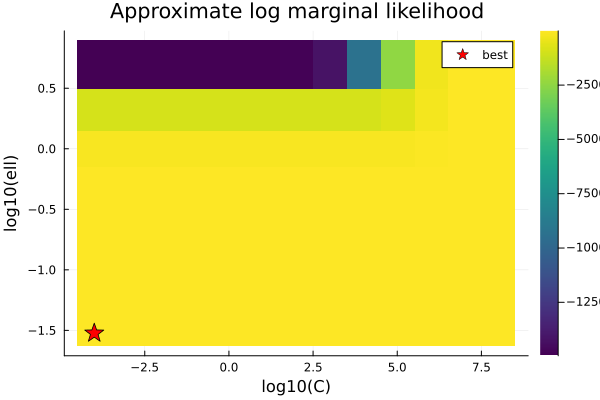

In [11]:
# ============================================================
# LML heatmap
# ============================================================

finite_vals = lml_table[isfinite.(lml_table)]
plot_floor =
    isempty(finite_vals) ? -1e6 : minimum(finite_vals)

LML_plot = copy(lml_table)
LML_plot[.!isfinite.(LML_plot)] .= plot_floor

p_lml = heatmap(
    log10.(C_grid),
    log10.(ell_grid),
    LML_plot;
    xlabel="log10(C)",
    ylabel="log10(ell)",
    title="Approximate log marginal likelihood",
    color=:viridis
)

scatter!(
    p_lml,
    [log10(best_C)],
    [log10(best_ell)];
    label="best",
    marker=:star5,
    markersize=10,
    color=:red
)

display(p_lml)


In [12]:
# ============================================================
# Posterior using the grid-search optimum
# ============================================================

K_best = Symmetric(
    kernel_matrix_2d(
        xy,
        xy;
        ν=nu_ker,
        ℓ=best_ell,
        σf=sigma_f
    ) + 1e-8*I
)

u_map_best = newton_map(
    dx,
    Nx,
    f_vals,
    K_best;
    C=best_C,
    tau=tau,
    u0=u_fdm,
    verbose=false
)

mu_best, std_best = laplace_posterior(
    u_map_best,
    xy,
    dx,
    Nx,
    K_best;
    C=best_C,
    tau=tau
)

err_fdm = maximum(abs.(u_fdm - u_star))
err_map = maximum(abs.(mu_best - u_star))

println("=== Training-grid errors ===")
@printf("FDM Linf       = %.6g\n", err_fdm)
@printf("Posterior Linf = %.6g\n", err_map)
@printf("max posterior std = %.6g\n", maximum(std_best))


=== Training-grid errors ===
FDM Linf       = 2.00517
Posterior Linf = 2.00517
max posterior std = 1.77067e-06


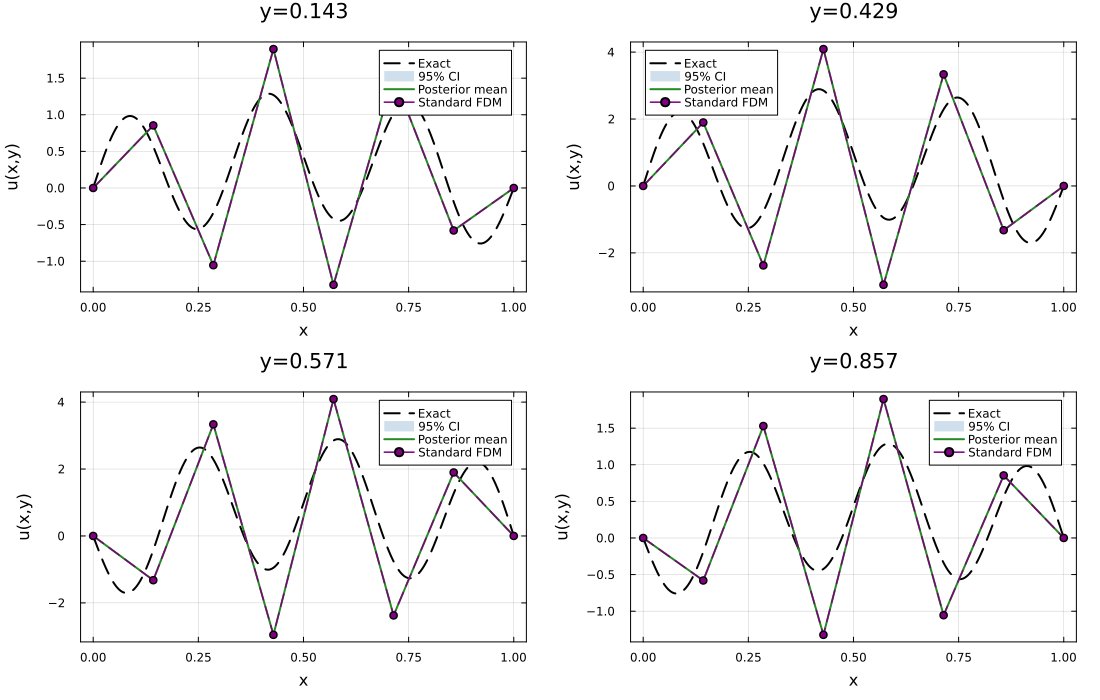

In [14]:
# ============================================================
# Simple slice visualization with boundary points
# ============================================================

xs = [dx*i for i in 1:Nx]
ys = [dx*j for j in 1:Nx]

U_true = reshape(u_star, Nx, Nx)'
U_fdm  = reshape(u_fdm, Nx, Nx)'
U_post = reshape(mu_best, Nx, Nx)'
U_std  = reshape(std_best, Nx, Nx)'

y_slices = [0.2, 0.4, 0.6, 0.8]

plots = []

for y0 in y_slices

    j = argmin(abs.(ys .- y0))
    y_actual = ys[j]

    # Exact: fine grid
    x_fine = collect(range(0.0, 1.0, length=501))

    exact_fine = [
        u_true(x, y_actual)
        for x in x_fine
    ]

    # --------------------------------------------------------
    # Add Dirichlet boundary values u=0
    # --------------------------------------------------------

    xs_plot = vcat(0.0, xs, 1.0)

    # Standard FDM
    u_fdm_plot = vcat(
        0.0,
        U_fdm[j,:],
        0.0
    )

    # Posterior mean
    u_post_plot = vcat(
        0.0,
        U_post[j,:],
        0.0
    )

    # Boundary condition is exact -> posterior std = 0
    u_std_plot = vcat(
        0.0,
        U_std[j,:],
        0.0
    )

    lower = u_post_plot .- 1.96 .* u_std_plot
    upper = u_post_plot .+ 1.96 .* u_std_plot

    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    pp = plot(
        x_fine,
        exact_fine;
        label="Exact",
        lw=2,
        ls=:dash,
        color=:black,
        xlabel="x",
        ylabel="u(x,y)",
        title="y=$(round(y_actual,digits=3))",
        framestyle=:box
    )

    # 95% CI
    plot!(
        pp,
        xs_plot,
        upper;
        fillrange=lower,
        fillalpha=0.25,
        linealpha=0,
        label="95% CI",
        color=:steelblue
    )

    # Posterior mean
    plot!(
        pp,
        xs_plot,
        u_post_plot;
        label="Posterior mean",
        lw=2,
        color=:forestgreen
    )

    # Standard FDM including boundary points
    plot!(
        pp,
        xs_plot,
        u_fdm_plot;
        label="Standard FDM",
        lw=1.5,
        ls=:dash,
        marker=:circle,
        markersize=4,
        color=:purple
    )

    push!(plots, pp)
end

fig = plot(
    plots...;
    layout=(2,2),
    size=(1100,700),
    margin=4*Plots.mm
)

display(fig)